---
title: MA and ARIMA modeling
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf


# MA Models

The MA($q$) model is given by: 
\begin{align*}
   y_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1} + \dots + \theta_q \epsilon_{t-q}
\end{align*}
The parameters are $\mu, \theta_1, \dots, \theta_q$ as well as $\sigma$ (note $\epsilon_t \overset{\text{i.i.d}}{\sim} N(0, \sigma^2)$).  

Usually the MA($q$) model is applicable either after some basic preprocessing involving differencing (such as $\log y_t - \log y_{t-1}$) or to residuals after fitting an AR model. Here is a simple standard example for fitting MA(1). 


## The Varve dataset

Consider the varve dataset from the Shumway and Stoffer book. It records the thickness of yearly glacial varves—layers of sediment deposited by melting glaciers—collected from a single site in Massachusetts. Each varve represents one year of sedimentation, formed when meltwater streams carried sand and silt into a glacial lake during the spring and summer melt seasons at the end of the last Ice Age. The dataset contains 634 annual measurements, covering a continuous period that began about 11,834 years ago, when the glaciers in New England were retreating. Thicker varves indicate warmer years with more melting and heavier sediment flow, while thinner varves reflect colder years with less melting. Although these deposits stopped forming thousands of years ago when the glacial lake drained, the preserved layers now provide scientists with a high-resolution record of past climate variations, helping reconstruct temperature and melting patterns during the planet’s transition out of the Ice Age.

See Example 2.6 of the Shumway-Stoffer book, 4th edition, for more details on the dataset.

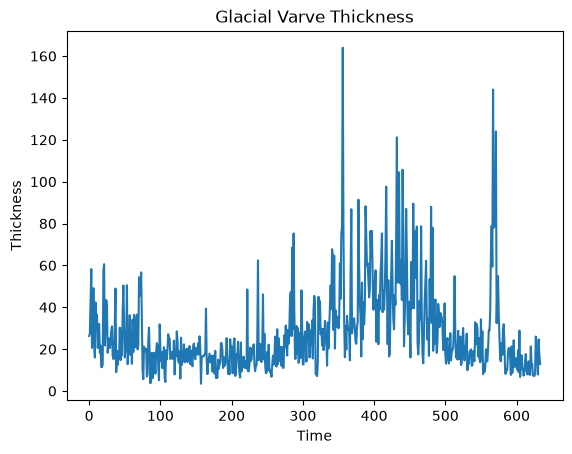

In [35]:
varve_data = pd.read_csv("varve.csv")
yraw = varve_data['x']
plt.plot(yraw)
plt.xlabel('Time')
plt.ylabel('Thickness')
plt.title('Glacial Varve Thickness')
plt.show()

We shall work with the logarithms of the raw data. 

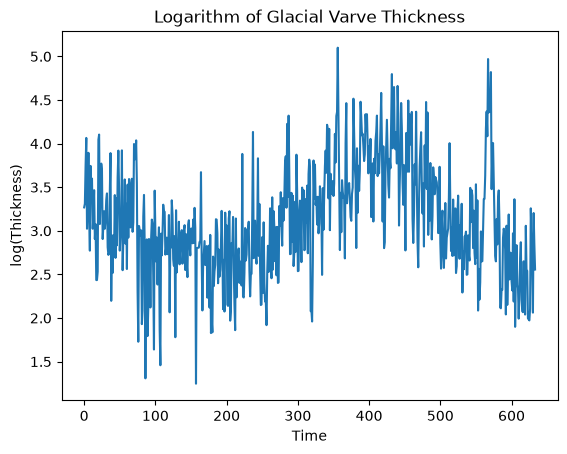

In [36]:
#We shall work with the logarithms: 
ylog = np.log(yraw)
plt.plot(ylog)
plt.xlabel('Time')
plt.ylabel('log(Thickness)')
plt.title('Logarithm of Glacial Varve Thickness')
plt.show()

Fitting a stationary model such as MA($q$) is not appropriate for the logarithmed data. This is because the data does not seem to have constant mean. To deal with this, we difference the data as follows. 

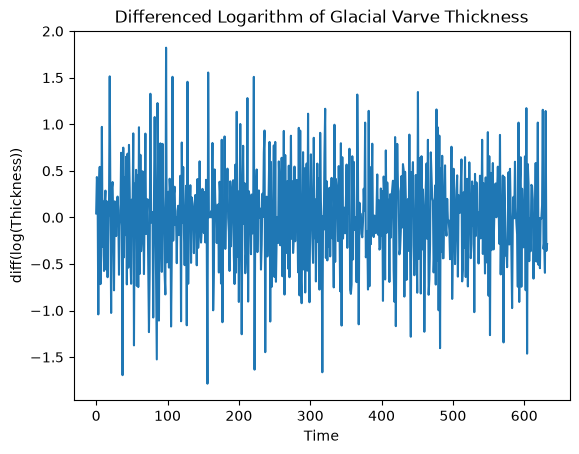

In [37]:
ylogdiff = np.diff(ylog)
plt.plot(ylogdiff)
plt.xlabel('Time')
plt.ylabel('diff(log(Thickness))')
plt.title('Differenced Logarithm of Glacial Varve Thickness')
plt.show()

Now let us look at the sample acf of this dataset. 

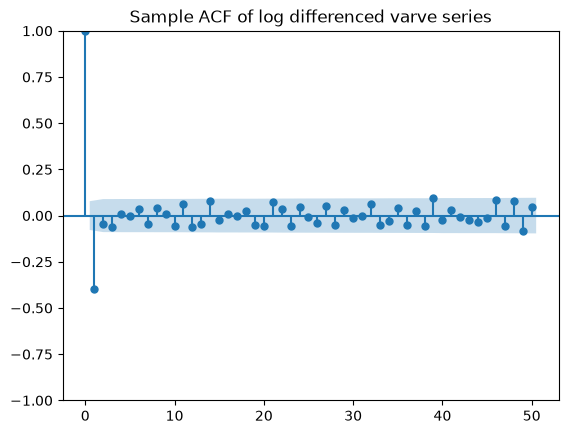

In [41]:
h_max = 50
fig, ax = plt.subplots() 
plot_acf(ylogdiff, lags = h_max, ax = ax)
ax.set_title("Sample ACF of log differenced varve series")
plt.show()

It is clear that the sample ACF shows one negative nonnegligible spike at lag one.  The other spikes seem insignificant. This is MA(1) behaviour which suggests that the MA(1) should be appropriate for this data (which is differenced logarithms of the varve data). 

## Fitting MA models using the ARIMA function

Fitting MA models to data is more complicated compared to AR models. We use an inbuilt function in statsmodels called ARIMA for this. ARIMA models (which we will define later) are determined by three orders $(p, d, q)$. $p$ denotes the AR order, $q$ denotes the MA order, and $d$ denotes differencing. To fit the MA(1) model, we take $p = 0, d = 0$ and $q = 1$. 

In [42]:
from statsmodels.tsa.arima.model import ARIMA
mamod = ARIMA(ylogdiff, order = (0, 0, 1)).fit()
print(mamod.summary())
print(mamod.params)
mu_hat = mamod.params[0]
theta_hat = mamod.params[1]
sigma_hat = np.sqrt(mamod.params[2])
print(f"mu_hat = {mu_hat: .4f}, theta_hat = {theta_hat: .4f}, sigma_hat = {sigma_hat: .4f}")

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  633
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -440.678
Date:                Thu, 05 Nov 2026   AIC                            887.356
Time:                        19:09:44   BIC                            900.707
Sample:                             0   HQIC                           892.541
                                - 633                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0013      0.004     -0.280      0.779      -0.010       0.008
ma.L1         -0.7710      0.023    -33.056      0.000      -0.817      -0.725
sigma2         0.2353      0.012     18.881      0.0

This ARIMA function can be applied on the log varve data also, instead of first differencing and then applying it on the differenced log data. If we are not using differencing data, we have to use d = 1 in the ARIMA function (i.e., $(p, d, q)
$  = $(0, 1, 1)$). 

In [44]:
mamod_ylog = ARIMA(ylog, order = (0, 1, 1)).fit()
print(mamod_ylog.summary())

                               SARIMAX Results                                
Dep. Variable:                      x   No. Observations:                  634
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -440.718
Date:                Thu, 05 Nov 2026   AIC                            885.435
Time:                        19:11:57   BIC                            894.336
Sample:                             0   HQIC                           888.892
                                - 634                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7705      0.023    -32.948      0.000      -0.816      -0.725
sigma2         0.2353      0.012     19.124      0.000       0.211       0.259
Ljung-Box (L1) (Q):                   9.10   Jarque-

Note now that there is no constant. This ARIMA function, by default, fits $y_t = \epsilon_t + \theta \epsilon_{t-1}$ (with no $\mu$ i.e., with $\mu = 0$) if the differencing order is strictly positive. 

## Fitting using conditional likelihood with $\epsilon_0 = 0$. 

Instead of using the ARIMA function, we can also try to use a first principles approach to estimate the parameters, by writing the conditional likelihood assuming $\epsilon_0 = 0$. 

Let $\hat{\epsilon}_1 = y_1 - \mu$ and, for $t = 2, \dots, n$, 
\begin{equation*}
    \hat{\epsilon}_t = y_t- \mu - \theta \hat{\epsilon}_{t-1} 
\end{equation*}
The sum of squares is given by: 
\begin{align*}
   S(\mu, \theta) := \sum_{t=1}^n \hat{\epsilon}_t^2
\end{align*}
so that the likelihood and log-likelihood become
\begin{align*}
   \text{likelihood} = \left(\frac{1}{\sigma \sqrt{2 \pi}} \right)^n \exp \left(-\frac{S(\mu, \theta)}{2 \sigma^2} \right)
\end{align*}
and 
\begin{align*}
   \text{log-likelihood} = -\frac{n}{2} \log (\sigma^2) - \frac{S(\mu, \theta)}{2 \sigma^2}. 
\end{align*}
Thus the MLEs of $\mu, \theta$ are obtained by minimizing $S(\mu, \theta)$, and the MLE of $\sigma$ is 
\begin{align*}
   \hat{\sigma} = \sqrt{\frac{S(\hat{\mu}, \hat{\theta})}{n}}
\end{align*}

Here is the code for the function $S(\mu, \theta)$. 

In [45]:
def S_func(params, y): #this is the function S(\mu, \theta)
    mu, theta = params
    n = len(y)
    eps = np.zeros(n)
    eps[0] = y[0] - mu
    for t in range(1, n):
        eps[t] = y[t] - mu - theta * eps[t-1]
    S_val = np.sum(eps**2)
    return S_val

We will use the function 'minimize' from scipy.optimize to minimize S_func. 

In [46]:
dt = ylogdiff

# Initial guess: [mu_init, theta_init]
mu_init = np.mean(dt)
theta_init = 0
init_params = [mu_init, theta_init]

# Perform the optimization
from scipy.optimize import minimize
result = minimize(S_func, init_params, args=(dt,))
print(result)
mu_hat, theta_hat = result.x

print("Estimated mu:", mu_hat)
print("Estimated theta:", theta_hat)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 149.00423625212122
        x: [-1.137e-03 -7.728e-01]
      nit: 12
      jac: [-3.815e-06 -1.907e-06]
 hess_inv: [[ 4.137e-05  5.724e-06]
            [ 5.724e-06  2.545e-03]]
     nfev: 63
     njev: 21
Estimated mu: -0.001136648493518346
Estimated theta: -0.7728310156211502


Let us compare the estimates obtained from the above code, with the estimates given by the ARIMA function.

In [47]:
print(result.x)
print(mamod.params)

[-0.00113665 -0.77283102]
[-0.00125667 -0.77099236  0.23528045]


The estimates are similar (the third estimate is that of $\sigma^2$). 

In [48]:
sigma_hat = np.sqrt(S_func(result.x, dt) / len(dt))
print("Estimated sigma:", sigma_hat)
print("MA reported sigma:", np.sqrt(mamod.params[2]))

Estimated sigma: 0.4851739256751231
MA reported sigma: 0.48505715819375406


The estimates of $\sigma$ are also similar. 

## Standard Errors corresponding to the parameter estimates

After obtaining the MLEs $\hat{\mu}$ and $\hat{\theta}$, the next step is to obtain standard errors. These are reported by the ARIMA function. We can also derive this using the Bayesian approach with the conditional likelihood. We use the Bayesian approach with the standard prior: 
\begin{align*}
   \mu, \theta, \log \sigma \overset{\text{i.i.d}}{\sim} \text{unif}(-C, C). 
\end{align*}

The posterior is then
\begin{align*}
  f_{\mu, \theta, \sigma \mid \text{data}}(\mu, \theta, \sigma) &\propto   \left(\frac{1}{\sqrt{2 \pi}\sigma}\right)^n  \exp
  \left(-\frac{S(\mu, \theta)}{2 \sigma^2} \right) \times 
                                                                  \frac{1}{\sigma}
                                                                  I\{
                                                                  -C <
                                                                  \mu, \theta,
                                                                  \log
                                                                  \sigma
                                                                  <
                                                                  C\}
  \\ 
  &\propto \sigma^{-n-1} \exp
  \left(-\frac{S(\mu, \theta)}{2 \sigma^2} \right) I\{
                                                                  -C <
                                                                  \mu, \theta,
                                                                  \log
                                                                  \sigma
                                                                  <
                                                                  C\}
\end{align*}
This is the joint posterior of $\mu, \theta, \sigma$. To obtain the posterior of $\mu, \theta$ (without $\sigma$), we integrate the above over $\sigma$ (from 0 to $\infty$). This integration is exactly the same as Lecture 4, and we get
\begin{align*}
   f_{\mu, \theta \mid \text{data}}(\mu, \theta) \propto \left(\frac{1}{S(\mu, \theta)} \right)^{n/2} I\{
                                                                  -C <
                                                                  \mu, \theta
                                                                  <
                                                                  C\} \propto \left(\frac{S(\hat{\mu}, \hat{\theta})}{S(\mu, \theta)} \right)^{n/2} I\{
                                                                  -C <
                                                                  \mu, \theta
                                                                  <
                                                                  C\}
\end{align*}
If $S(\mu, \theta)$ is a quadratic function of $\mu, \theta$, then this will be a $t$-density. However our $S(\mu, \theta)$ will involve higher powers of $\theta$ and is not quadratic. The posterior usually is fairly concentrated around the MLE $(\hat{\mu}, \hat{\theta})$ though, so we it makes sense to approximate $S(\mu, \theta)$ by a quadratic around $(\hat{\mu}, \hat{\theta})$. This is done by Taylor expansion as follows. Let $\alpha = (\mu, \theta)$ and $\hat{\alpha} =
(\hat{\mu}, \hat{\theta})$. Taylor expansion for $\alpha$ near
$\hat{\alpha}$ gives 
\begin{align*}
  S(\alpha) &= S(\hat{\alpha}) + \left<\nabla S(\hat{\alpha}), \alpha
              - \hat{\alpha} \right> + \left(\alpha - \hat{\alpha}
              \right)^T \left(\frac{1}{2} HS(\hat{\alpha}) \right) \left(\alpha - \hat{\alpha}
              \right) \\
  &= S(\hat{\alpha}) + \left(\alpha - \hat{\alpha}
              \right)^T \left(\frac{1}{2} HS(\hat{\alpha}) \right) \left(\alpha - \hat{\alpha}
              \right)
\end{align*}
where we used $\nabla S(\hat{\alpha}) = 0$ because $\hat{\alpha}$
minimizes $S(\alpha)$. Here $HS(\hat{\alpha})$ denotes the Hessian of
$S$ at $\hat{\alpha}$.  

Therefore
\begin{align*}
 & f_{\mu, \theta \mid \text{data}}(\mu, \theta) \\ &\propto
                                                  \left(\frac{1}{S(\mu,
                                                  \theta)}
                                                  \right)^{n/2}  I\{
                                                  -C < \mu, \theta < C\} \\
  &\propto \left(\frac{S(\hat{\alpha})}{S(\alpha)}
                                                  \right)^{n/2}  I\{
    -C < \mu, \theta < C\} \\
  &= \left(\frac{S(\hat{\alpha})}{S(\hat \alpha) + \left(\alpha - \hat{\alpha}
              \right)^T \left(\frac{1}{2} HS(\hat{\alpha}) \right) \left(\alpha - \hat{\alpha}
              \right)}
                                                  \right)^{n/2}  I\{-C < \mu, \theta < C\} \\
  &= \left(\frac{1}{1 + \left(\alpha - \hat{\alpha}
              \right)^T \left(\frac{1}{2 S(\hat{\alpha})} HS(\hat{\alpha}) \right) \left(\alpha - \hat{\alpha}
              \right)}
                                                  \right)^{n/2}  I\{-C < \mu, \theta < C\} \\
  &= \left(\frac{1}{1 + \frac{1}{n-2}\left(\alpha - \hat{\alpha}
              \right)^T \left(\frac{n-2}{2 S(\hat{\alpha})} HS(\hat{\alpha}) \right) \left(\alpha - \hat{\alpha}
              \right)}
                                                  \right)^{\frac{n-2+2}{2}}  I\{-C < \mu, \theta < C\}. 
\end{align*}
Comparing the above with the formula:
\begin{align*}
  \left(\frac{1}{1 + \frac{1}{k} (x - m)^T \Sigma^{-1} (x - m)} \right)^{\frac{k + p}{2}}
\end{align*}
for the $p$-variate $t$-density $t_{k, p}(\mu, \Sigma)$, we see that
(ignoring the indicator function $ I\{-C < \mu, \theta < C\}$)
\begin{align*}
  \alpha \mid \text{data} \sim t_{n-2, 2} \left(\hat{\alpha},
  \frac{S(\hat{\alpha})}{n - 2} \left(\frac{1}{2} HS(\hat{\alpha})
  \right)^{-1} \right). 
\end{align*}
So the standard errors corresponding to $\mu$ and $\theta$ can be obtained by taking the square roots of the diagonal entries of 
\begin{align*}
\frac{S(\hat{\alpha})}{n - 2} \left(\frac{1}{2} HS(\hat{\alpha})
  \right)^{-1}
\end{align*}
In order to compute these, we need to calculate the Hessian of $S(\alpha)$ with respect to $\alpha$. We will use numerical differentiation (specifically a function from the library numdifftools) for this. 


In [49]:
import numdifftools as nd #this library has functions to calculate first and second derivatives 
alphaest = result.x
n = len(dt)
H = nd.Hessian(lambda alpha: S_func(alpha, dt), step = 1e-6)(alphaest)

sighat = np.sqrt(S_func(alphaest, dt) / (n - 2))
covmat = (sighat ** 2) * np.linalg.inv(0.5 * H)
stderrs = np.sqrt(np.diag(covmat))

# ---- Output ----
print("Estimated mu:", alphaest[0])
print("Estimated theta:", alphaest[1])
print("Estimated sigma:", sighat)
print("Covariance matrix:\n", covmat)
print("Standard errors:", stderrs)

#The standard errors of mu and theta reported by ARIMA function are:
print("MA standard errors:", mamod.bse[0:2])

Estimated mu: -0.001136648493518346
Estimated theta: -0.7728310156211502
Estimated sigma: 0.4859422142413731
Covariance matrix:
 [[1.94152431e-05 8.28638953e-07]
 [8.28638953e-07 1.17034005e-03]]
Standard errors: [0.00440627 0.03421023]
MA standard errors: [0.00448462 0.02332403]


The standard error corresponding to $\theta$ that we computed is a little off from the one reported by the ARIMA function, but the standard errors corresponding to $\mu$ are almost the same. 

Note that we did not calculate standard errors for $\sigma$. This can be done by calculating the posterior of $\sigma$ (this can be written in terms of the chi-squared distribution). 

The ARIMA function works with the full likelihood unlike the analysis above which works with the conditional likelihood (conditioning on $\epsilon_0 = 0$). So the answers will be slightly different. The full likelihood is more complicated to write down. 

There are actually multiple ways of computing the standard errors. The default option in ARIMA uses  'opg' (outer product of gradients). Instead if we use another option called 'approx', we get answers that are quite similar to the standard errors that we computed. 

In [71]:
mamod = ARIMA(ylogdiff, order = (0, 0, 1)).fit(cov_type = 'approx')
print(mamod.summary())
print("MA standard errors:", mamod.bse[0:2])
print("Standard errors:", stderrs)

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  633
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -440.678
Date:                Fri, 06 Nov 2026   AIC                            887.356
Time:                        20:24:52   BIC                            900.707
Sample:                             0   HQIC                           892.541
                                - 633                                         
Covariance Type:               approx                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0013      0.004     -0.283      0.777      -0.010       0.007
ma.L1         -0.7710      0.034    -22.600      0.000      -0.838      -0.704
sigma2         0.2353      0.013     17.791      0.0

In [ ]:
print("Standard errors:", stderrs)
#The standard errors of mu and theta reported by ARIMA function are:
print("MA standard errors:", mamod.bse[0:2])

## GDP Dataset

In the last couple of lectures, we looked at the GDP dataset. 

  observation_date      GDP
0       1947-01-01  243.164
1       1947-04-01  245.968
2       1947-07-01  249.585
3       1947-10-01  259.745
4       1948-01-01  265.742


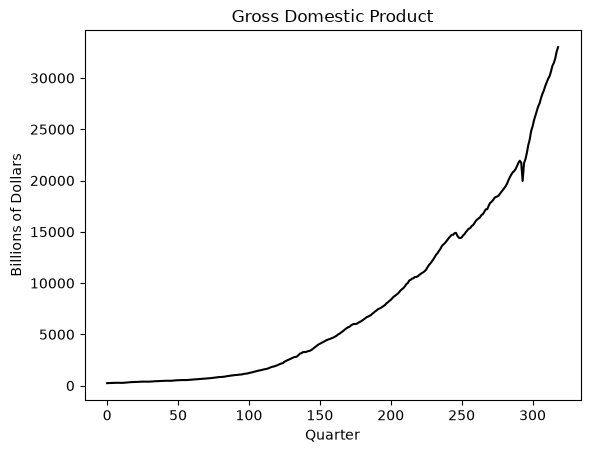

In [72]:
gdp = pd.read_csv('GDP_29Oct2026.csv')
print(gdp.head())
y = gdp['GDP'].to_numpy()
plt.plot(y, color = 'black')
plt.xlabel('Quarter')
plt.ylabel('Billions of Dollars')
plt.title('Gross Domestic Product')
plt.show()

We split this into training and test datasets as follows. 

In [52]:
n = len(y)
tme = range(1, n+1)
n_test = 50
#n_test = 12 
n_train = n - n_test
y_train = y[:n_train]
tme_train = tme[:n_train]
y_test = y[n_train:]
tme_test = tme[n_train:]

We fit models to logarithms of the raw data. 

In [53]:
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

In the last lecture (Lecture 19), we fit the AR(4) model to the training data. In Lecture 18, we fit AR(1). Below, we re-fit these models and then check out the obtained residuals. 

In [ ]:
p = 4
#p = 1
armod = AutoReg(ylog_train, lags = p).fit()
print(armod.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  269
Model:                     AutoReg(4)   Log Likelihood                 863.305
Method:               Conditional MLE   S.D. of innovations              0.009
Date:                Thu, 05 Nov 2026   AIC                          -1714.610
Time:                        19:31:53   BIC                          -1693.131
Sample:                             4   HQIC                         -1705.980
                                  269                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0141      0.004      3.654      0.000       0.007       0.022
y.L1           1.4221      0.060     23.637      0.000       1.304       1.540
y.L2          -0.1959      0.103     -1.904      0.0

Let us look at the residuals of the fitted AR model. 

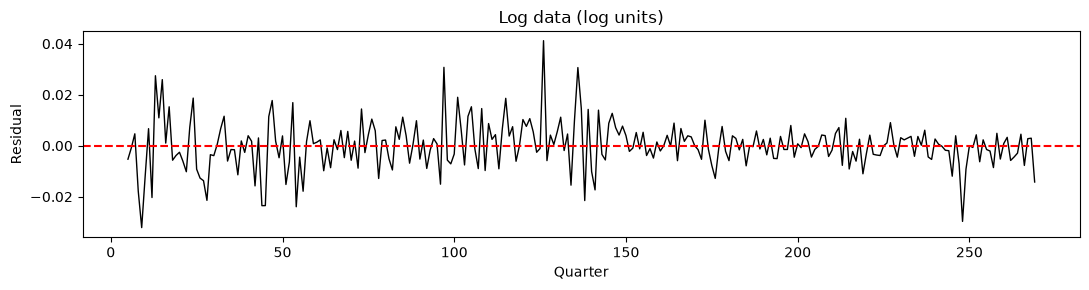

In [58]:
resid_log = armod.resid

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(tme_train[p:], resid_log, color='black', linewidth=1)
ax.axhline(0, color='red', linestyle='--')
ax.set(title='Log data (log units)', xlabel='Quarter', ylabel='Residual')
plt.tight_layout()
plt.show()

Below we plot the sample ACF of the residuals of the fitted AR model. 

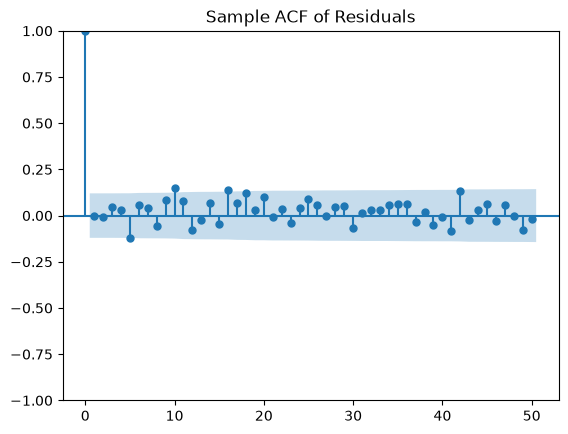

In [59]:
h_max = 50
fig, ax = plt.subplots() 
plot_acf(resid_log, lags = h_max, ax = ax)
ax.set_title("Sample ACF of Residuals")
plt.show()

The AR(4) residuals do not have any autocorrelations, so i.i.d $N(0, \sigma^2)$ is a good assumption for the errors in AR(4). But the AR(1) residuals have many autocorrelations including at lags 1 and 2. Below we look at the predictions obtained by AR(4), and also AR(1) followed by MA(2) for the residuals, and also ARMA(1, 2) applied directly. 

Here are the predictions for the AR(4) model and its prediction error (MSE on the log-scale).

In [60]:
# Predictions on the log scale
p = 4
armod = AutoReg(ylog_train, lags = p).fit()

n_train = len(ylog_train)
k = len(ylog_test)

fcast = armod.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean_ar4 = np.asarray(fcast.predicted_mean)

# Test MSE on the log scale
mse_ar4 = np.mean((np.asarray(ylog_test) - fcast_mean_ar4)**2)
print("Test MSE (log scale):", mse_ar4)

Test MSE (log scale): 0.0015580683441375326


Next we fit ARMA(1, 2). If we use ARIMA(data, order = (1, 0, 2)), the resulting predictions are not very good. This is because the default method for fitting parameters tries to force the parameters into certain regions (the so-called 'stationary' regions) which is not a good thing in this dataset. It is better to not enforce any such contraints. For the ARIMA function, this explicitly requires the option enforce_stationarity = False in some cases. 

In [63]:
# Fit ARMA(1, 2) to the log data (d = 0 means no differencing)
armamod = ARIMA(ylog_train, order = (1, 0, 2), enforce_stationarity = False).fit() 
#armamod = ARIMA(ylog_train, order = (1, 0, 2)).fit() 
print(armamod.summary())
n_train = len(ylog_train)
k = len(ylog_test)

# Predictions on the log scale
fcast = armamod.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean_arma12 = np.asarray(fcast.predicted_mean)

# Test MSE on the log scale
mse_arma12 = np.mean((np.asarray(ylog_test) - fcast_mean_arma12)**2)
print("Test MSE (log scale):", mse_arma12)

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  269
Model:                 ARIMA(1, 0, 2)   Log Likelihood                 861.010
Date:                Thu, 05 Nov 2026   AIC                          -1712.021
Time:                        19:35:13   BIC                          -1694.103
Sample:                             0   HQIC                         -1704.822
                                - 269                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.7107      3.389      4.635      0.000       9.068      22.354
ar.L1          0.9980      0.001   1277.482      0.000       0.996       1.000
ma.L1          0.3951      0.045      8.819      0.0

Below we plot the predictions for the two models (AR(4) and ARMA(1, 2)) along with the actual data. 

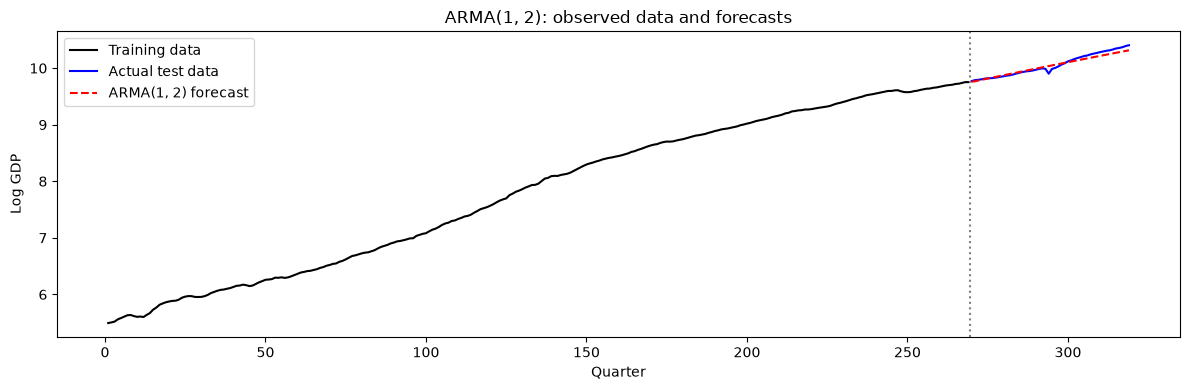

In [65]:
import matplotlib.pyplot as plt

t_train = np.arange(1, n_train+1)
t_test = np.arange(n_train+1, n_train+k+1)

plt.figure(figsize = (12, 4))
plt.plot(t_train, ylog_train, color = 'black', label = 'Training data')
plt.plot(t_test, ylog_test, color = 'blue', label = 'Actual test data')
plt.plot(t_test, fcast_mean_arma12, color = 'red', linestyle = '--',
         label = 'ARMA(1, 2) forecast')

plt.axvline(n_train + 0.5, color = 'grey', linestyle = ':')
plt.xlabel('Quarter')
plt.ylabel('Log GDP')
plt.title('ARMA(1, 2): observed data and forecasts')
plt.legend()
plt.tight_layout()
plt.show()

Instead of fitting ARMA(1, 2) directly, we can first fit AR(1) and then MA(2) to the residuals. This is implemented below. We also obtain predictions here in the following way. We first obtain predictions for the fitted MA(2) model, then we combine with the AR(1) equation to get predictions which can be compared with the test data. 

In [67]:
# Fit AR(1), then a zero-mean MA(2) to its residuals
p = 1
armod_sm = AutoReg(ylog_train, lags = p).fit()
print(armod_sm.summary())
resid_log = np.asarray(armod_sm.resid)
mamod = ARIMA(resid_log, order = (0, 0, 2), trend = 'n').fit()
print(mamod.summary())

n_train = len(ylog_train)
k = len(ylog_test)

# Predictions for the MA(2) residual process
n_resid = len(resid_log)
fcast_ma = mamod.get_prediction(start = n_resid, end = n_resid+k-1)
ma_predictions = np.asarray(fcast_ma.predicted_mean)

# AR predictions with the predicted MA residual added at each step
yhat = np.concatenate([np.asarray(ylog_train, dtype = float),
                       np.full(k, -9999.)])
phi_vals = np.asarray(armod_sm.params)

for i in range(1, k+1):
    ans = phi_vals[0]
    for j in range(1, p+1):
        ans += phi_vals[j] * yhat[n_train+i-j-1]
    ans += ma_predictions[i-1]
    yhat[n_train+i-1] = ans

fcast_mean_arthenma = yhat[n_train:]

# Test MSE on the log scale
mse_arthenma = np.mean((np.asarray(ylog_test) - fcast_mean_arthenma)**2)
print("Test MSE (log scale):", mse_arthenma)

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  269
Model:                     AutoReg(1)   Log Likelihood                 830.433
Method:               Conditional MLE   S.D. of innovations              0.011
Date:                Thu, 05 Nov 2026   AIC                          -1654.866
Time:                        19:38:19   BIC                          -1644.093
Sample:                             1   HQIC                         -1650.539
                                  269                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0283      0.004      7.232      0.000       0.021       0.036
y.L1           0.9984      0.000   2014.926      0.000       0.997       0.999
                                    Roots           

Below we plot the predictions for all the three models.

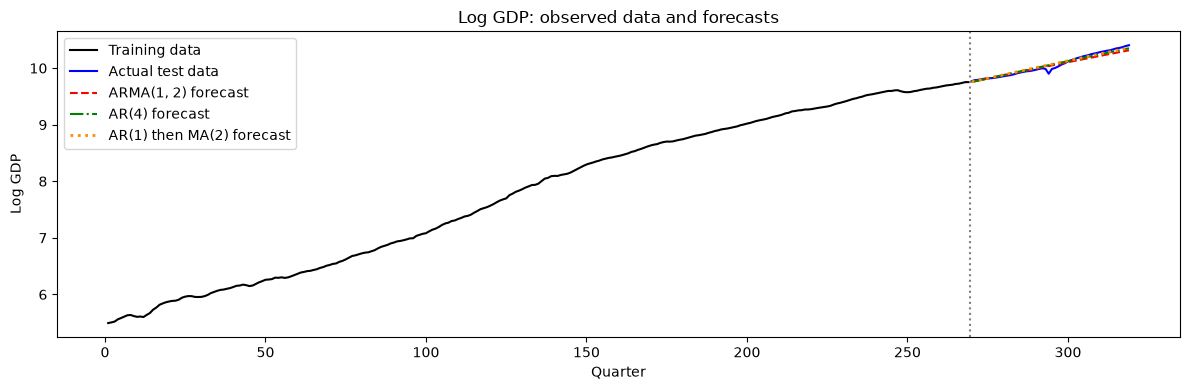

In [68]:
t_train = np.arange(1, n_train+1)
t_test = np.arange(n_train+1, n_train+k+1)

plt.figure(figsize = (12, 4))
plt.plot(t_train, ylog_train, color = 'black', label = 'Training data')
plt.plot(t_test, ylog_test, color = 'blue', label = 'Actual test data')

plt.plot(t_test, fcast_mean_arma12, color = 'red', linestyle = '--',
         label = 'ARMA(1, 2) forecast')
plt.plot(t_test, fcast_mean_ar4, color = 'green', linestyle = '-.',
         label = 'AR(4) forecast')
plt.plot(t_test, fcast_mean_arthenma, color = 'darkorange', linestyle = ':',
         linewidth = 2, label = 'AR(1) then MA(2) forecast')

plt.axvline(n_train + 0.5, color = 'grey', linestyle = ':')
plt.xlabel('Quarter')
plt.ylabel('Log GDP')
plt.title('Log GDP: observed data and forecasts')
plt.legend()
plt.tight_layout()
plt.show()

To better see the differences between the predictions, we zoom into the predictions. 

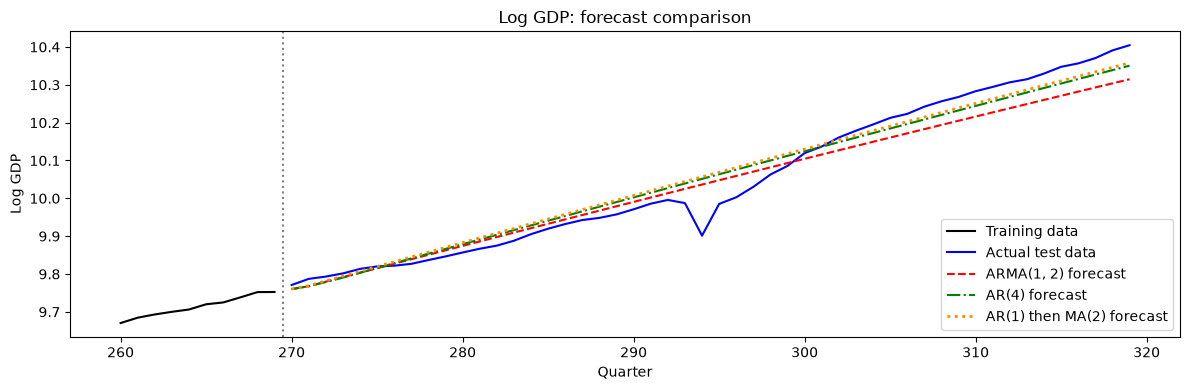

In [69]:
n_show = 10  # Number of training observations to display

t_train = np.arange(1, n_train+1)
t_test = np.arange(n_train+1, n_train+k+1)

plt.figure(figsize = (12, 4))
plt.plot(t_train[-n_show:], np.asarray(ylog_train)[-n_show:],
         color = 'black', label = 'Training data')
plt.plot(t_test, ylog_test, color = 'blue', label = 'Actual test data')

plt.plot(t_test, fcast_mean_arma12, color = 'red', linestyle = '--',
         label = 'ARMA(1, 2) forecast')
plt.plot(t_test, fcast_mean_ar4, color = 'green', linestyle = '-.',
         label = 'AR(4) forecast')
plt.plot(t_test, fcast_mean_arthenma, color = 'darkorange', linestyle = ':',
         linewidth = 2, label = 'AR(1) then MA(2) forecast')

plt.axvline(n_train + 0.5, color = 'grey', linestyle = ':')
plt.xlabel('Quarter')
plt.ylabel('Log GDP')
plt.title('Log GDP: forecast comparison')
plt.legend()
plt.tight_layout()
plt.show()

The AR(4) and AR(1)-MA(2) predictions are quite close to each other. The ARMA(1, 2) predictions also agree with these for the initial future period but they depart after a few quarters.

Below we loop over all ARIMA(p, d, q) models with p, q at most 5 and d at most 2, and then find the best model in terms of the model selection criteria AIC and BIC. 

In [70]:
import warnings
warnings.filterwarnings("ignore") #this suppresses convergence warnings. 

dt = ylog_train
pmax, dmax, qmax = 5, 2, 5

results = []

for p in range(pmax + 1):
    for d in range(dmax + 1):
        for q in range(qmax + 1):
            try:
                model = ARIMA(dt, order=(p, d, q), enforce_stationarity = False).fit()

                results.append({
                    'p': p, 'd': d, 'q': q,
                    'AIC': model.aic,
                    'BIC': model.bic
                })
            except Exception as e:
                print(f"ARIMA({p},{d},{q}) failed: {e}")
                continue

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Find best models
best_aic_model = results_df.loc[results_df['AIC'].idxmin()]
best_bic_model = results_df.loc[results_df['BIC'].idxmin()]

print("Best model by AIC:")
print(best_aic_model)

print("\nBest model by BIC:")
print(best_bic_model)

Best model by AIC:
p         1.000000
d         0.000000
q         2.000000
AIC   -1712.020578
BIC   -1694.103096
Name: 20, dtype: float64

Best model by BIC:
p         1.000000
d         0.000000
q         2.000000
AIC   -1712.020578
BIC   -1694.103096
Name: 20, dtype: float64


It is interesting that this automatic model selection approach also selects the model ARMA(1, 2). 